# Data Loading & Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('smartphones.csv')
df.head()

,model,price,rating,sim,processor,ram,battery,display,camera,card,os
0,OnePlus 11 5G,"₹54,999",89.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi, NFC","Snapdragon 8 Gen2, Octa Core, 3.2 GHz Processor","12 GB RAM, 256 GB inbuilt",5000 mAh Battery with 100W Fast Charging,"6.7 inches, 1440 x 3216 px, 120 Hz Display wit...",50 MP + 48 MP + 32 MP Triple Rear & 16 MP Fron...,Memory Card Not Supported,Android v13
1,OnePlus Nord CE 2 Lite 5G,"₹19,989",81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor","6 GB RAM, 128 GB inbuilt",5000 mAh Battery with 33W Fast Charging,"6.59 inches, 1080 x 2412 px, 120 Hz Display wi...",64 MP + 2 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12
2,Samsung Galaxy A14 5G,"₹16,499",75.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Exynos 1330, Octa Core, 2.4 GHz Processor","4 GB RAM, 64 GB inbuilt",5000 mAh Battery with 15W Fast Charging,"6.6 inches, 1080 x 2408 px, 90 Hz Display with...",50 MP + 2 MP + 2 MP Triple Rear & 13 MP Front ...,"Memory Card Supported, upto 1 TB",Android v13
3,Motorola Moto G62 5G,"₹14,999",81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor","6 GB RAM, 128 GB inbuilt",5000 mAh Battery with Fast Charging,"6.55 inches, 1080 x 2400 px, 120 Hz Display wi...",50 MP + 8 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12
4,Realme 10 Pro Plus,"₹24,999",82.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Dimensity 1080, Octa Core, 2.6 GHz Processor","6 GB RAM, 128 GB inbuilt",5000 mAh Battery with 67W Fast Charging,"6.7 inches, 1080 x 2412 px, 120 Hz Display wit...",108 MP + 8 MP + 2 MP Triple Rear & 16 MP Front...,Memory Card Not Supported,Android v13


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   model      1020 non-null   str    
 1   price      1020 non-null   str    
 2   rating     879 non-null    float64
 3   sim        1020 non-null   str    
 4   processor  1020 non-null   str    
 5   ram        1020 non-null   str    
 6   battery    1020 non-null   str    
 7   display    1020 non-null   str    
 8   camera     1019 non-null   str    
 9   card       1013 non-null   str    
 10  os         1003 non-null   str    
dtypes: float64(1), str(10)
memory usage: 408.8 KB


In [4]:
df.describe()

,rating
count,879.000000
mean,78.258248
std,7.402854
min,60.000000
25%,74.000000
50%,80.000000
75%,84.000000
max,89.000000


# Data Preprocessing & Feature Extraction

In [5]:

df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum() 

model          0
price          0
rating       141
sim            0
processor      0
ram            0
battery        0
display        0
camera         1
card           7
os            17
dtype: int64

In [7]:


df['rating'].fillna(df['rating'].mean(), inplace=True)
df.dropna(subset = ['os','camera','card'], inplace = True)
df.isnull().sum()

C:\Users\Keshav Gupta\AppData\Local\Temp\ipykernel_4756\3882044421.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['rating'].fillna(df['rating'].mean(), inplace=True)


model          0
price          0
rating       124
sim            0
processor      0
ram            0
battery        0
display        0
camera         0
card           0
os             0
dtype: int64

In [9]:
df['price'] = df['price'].str.replace('₹','').str.replace(',','')
df['price'] = pd.to_numeric(df['price'], errors = 'coerce')


that we extract only the essential value

In [10]:
#split the data in two set that was commma seprate 
df[['temp_ram', 'temp_stor']] = df['ram'].str.split(',',expand = True)

#extract an only numerical value from the text data
df['ram_gb'] = df['temp_ram'].str.extract(r'(\d+)')
df['stor_gb'] = df['temp_stor'].str.extract(r'(\d+)')

#convert an both of of them into the numerical format
df['ram_gb'] = pd.to_numeric(df['ram_gb'], errors = 'coerce')
df['stor_gb'] = pd.to_numeric(df['stor_gb'], errors = 'coerce')

#delete the temporay data coloum from the data we create that was an:-
df.drop(columns=['temp_ram','temp_stor','ram'], inplace=True)

df.head() #check that the it' is the correct or  not

,model,price,rating,sim,processor,battery,display,camera,card,os,ram_gb,stor_gb
0,OnePlus 11 5G,54999,89.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi, NFC","Snapdragon 8 Gen2, Octa Core, 3.2 GHz Processor",5000 mAh Battery with 100W Fast Charging,"6.7 inches, 1440 x 3216 px, 120 Hz Display wit...",50 MP + 48 MP + 32 MP Triple Rear & 16 MP Fron...,Memory Card Not Supported,Android v13,12.0,256.0
1,OnePlus Nord CE 2 Lite 5G,19989,81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor",5000 mAh Battery with 33W Fast Charging,"6.59 inches, 1080 x 2412 px, 120 Hz Display wi...",64 MP + 2 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12,6.0,128.0
2,Samsung Galaxy A14 5G,16499,75.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Exynos 1330, Octa Core, 2.4 GHz Processor",5000 mAh Battery with 15W Fast Charging,"6.6 inches, 1080 x 2408 px, 90 Hz Display with...",50 MP + 2 MP + 2 MP Triple Rear & 13 MP Front ...,"Memory Card Supported, upto 1 TB",Android v13,4.0,64.0
3,Motorola Moto G62 5G,14999,81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor",5000 mAh Battery with Fast Charging,"6.55 inches, 1080 x 2400 px, 120 Hz Display wi...",50 MP + 8 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12,6.0,128.0
4,Realme 10 Pro Plus,24999,82.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Dimensity 1080, Octa Core, 2.6 GHz Processor",5000 mAh Battery with 67W Fast Charging,"6.7 inches, 1080 x 2412 px, 120 Hz Display wit...",108 MP + 8 MP + 2 MP Triple Rear & 16 MP Front...,Memory Card Not Supported,Android v13,6.0,128.0


In [11]:
#that we process in the battery and take only numeric value
df['battery_mah'] = df['battery'].str.extract(r'(\d+)') #mah battery we take
df['battery_mah'] = pd.to_numeric(df['battery_mah'], errors = 'coerce')

#that we conert the fast charing:-
df['fast_chr_watt'] = df['battery'].str.extract(r'(\d+)\s*[Ww]') #mah battery we take
df['fast_chr_watt'] = df['fast_chr_watt'].fillna(0)

#remove that withiut using colunm
df.drop(columns=['battery'],inplace=True)
df.head()

,model,price,rating,sim,processor,display,camera,card,os,ram_gb,stor_gb,battery_mah,fast_chr_watt
0,OnePlus 11 5G,54999,89.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi, NFC","Snapdragon 8 Gen2, Octa Core, 3.2 GHz Processor","6.7 inches, 1440 x 3216 px, 120 Hz Display wit...",50 MP + 48 MP + 32 MP Triple Rear & 16 MP Fron...,Memory Card Not Supported,Android v13,12.0,256.0,5000,100
1,OnePlus Nord CE 2 Lite 5G,19989,81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor","6.59 inches, 1080 x 2412 px, 120 Hz Display wi...",64 MP + 2 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12,6.0,128.0,5000,33
2,Samsung Galaxy A14 5G,16499,75.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Exynos 1330, Octa Core, 2.4 GHz Processor","6.6 inches, 1080 x 2408 px, 90 Hz Display with...",50 MP + 2 MP + 2 MP Triple Rear & 13 MP Front ...,"Memory Card Supported, upto 1 TB",Android v13,4.0,64.0,5000,15
3,Motorola Moto G62 5G,14999,81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor","6.55 inches, 1080 x 2400 px, 120 Hz Display wi...",50 MP + 8 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12,6.0,128.0,5000,0
4,Realme 10 Pro Plus,24999,82.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Dimensity 1080, Octa Core, 2.6 GHz Processor","6.7 inches, 1080 x 2412 px, 120 Hz Display wit...",108 MP + 8 MP + 2 MP Triple Rear & 16 MP Front...,Memory Card Not Supported,Android v13,6.0,128.0,5000,67


In [12]:
#that take an brand name
df['brand'] = df['model'].str.split(' ').str.get(0)
df['brand'].value_counts()

brand
Xiaomi       135
Samsung      132
Vivo         111
Realme        97
OPPO          62
Motorola      52
Apple         47
OnePlus       42
Tecno         33
iQOO          32
Infinix       29
Poco          28
Oppo          26
Nokia         24
Huawei        16
Google        14
POCO          13
Honor         13
itel          10
Sony           9
Asus           7
Nubia          6
Nothing        5
Jio            5
iKall          4
Lava           4
Gionee         3
Letv           3
Redmi          3
Oukitel        3
Lyf            3
Itel           3
LG             3
Micromax       3
Royole         2
ZTE            2
Lenovo         2
Doogee         2
Tesla          1
Cola           1
LeEco          1
Duoqin         1
Vertu          1
BLU            1
Eunity         1
Leitz          1
CAT            1
DIZO           1
BlackZone      1
TCL            1
Sharp          1
Blackview      1
XTouch         1
Name: count, dtype: int64

In [13]:
df

,model,price,rating,sim,processor,display,camera,card,os,ram_gb,stor_gb,battery_mah,fast_chr_watt,brand
0,OnePlus 11 5G,54999,89.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi, NFC","Snapdragon 8 Gen2, Octa Core, 3.2 GHz Processor","6.7 inches, 1440 x 3216 px, 120 Hz Display wit...",50 MP + 48 MP + 32 MP Triple Rear & 16 MP Fron...,Memory Card Not Supported,Android v13,12.0,256.0,5000,100,OnePlus
1,OnePlus Nord CE 2 Lite 5G,19989,81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor","6.59 inches, 1080 x 2412 px, 120 Hz Display wi...",64 MP + 2 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12,6.0,128.0,5000,33,OnePlus
2,Samsung Galaxy A14 5G,16499,75.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Exynos 1330, Octa Core, 2.4 GHz Processor","6.6 inches, 1080 x 2408 px, 90 Hz Display with...",50 MP + 2 MP + 2 MP Triple Rear & 13 MP Front ...,"Memory Card Supported, upto 1 TB",Android v13,4.0,64.0,5000,15,Samsung
3,Motorola Moto G62 5G,14999,81.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 695, Octa Core, 2.2 GHz Processor","6.55 inches, 1080 x 2400 px, 120 Hz Display wi...",50 MP + 8 MP + 2 MP Triple Rear & 16 MP Front ...,"Memory Card (Hybrid), upto 1 TB",Android v12,6.0,128.0,5000,0,Motorola
4,Realme 10 Pro Plus,24999,82.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Dimensity 1080, Octa Core, 2.6 GHz Processor","6.7 inches, 1080 x 2412 px, 120 Hz Display wit...",108 MP + 8 MP + 2 MP Triple Rear & 16 MP Front...,Memory Card Not Supported,Android v13,6.0,128.0,5000,67,Realme
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,Motorola Moto Edge S30 Pro,34990,83.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 8 Gen1, Octa Core, 3 GHz Processor","6.67 inches, 1080 x 2460 px, 120 Hz Display wi...",64 MP + 8 MP + 2 MP Triple Rear & 16 MP Front ...,Android v12,No FM Radio,8.0,128.0,5000,2,Motorola
1016,Honor X8 5G,14990,75.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi","Snapdragon 480+, Octa Core, 2.2 GHz Processor","6.5 inches, 720 x 1600 px Display with Water D...",48 MP + 2 MP + Depth Sensor Triple Rear & 8 MP...,"Memory Card Supported, upto 1 TB",Android v11,6.0,128.0,5000,5,Honor
1017,POCO X4 GT 5G (8GB RAM + 256GB),28990,85.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi, NFC, IR Bl...","Dimensity 8100, Octa Core, 2.85 GHz Processor","6.6 inches, 1080 x 2460 px, 144 Hz Display wit...",64 MP + 8 MP + 2 MP Triple Rear & 16 MP Front ...,Memory Card Not Supported,Android v12,8.0,256.0,5080,67,POCO
1018,Motorola Moto G91 5G,19990,80.0,"Dual Sim, 3G, 4G, 5G, VoLTE, Wi-Fi, NFC","Snapdragon 695, Octa Core, 2.2 GHz Processor","6.8 inches, 1080 x 2400 px Display with Punch ...",108 MP + 8 MP + 2 MP Triple Rear & 32 MP Front...,"Memory Card Supported, upto 1 TB",Android v12,6.0,128.0,5000,0,Motorola


# Exploratory Data Analysis (EDA)

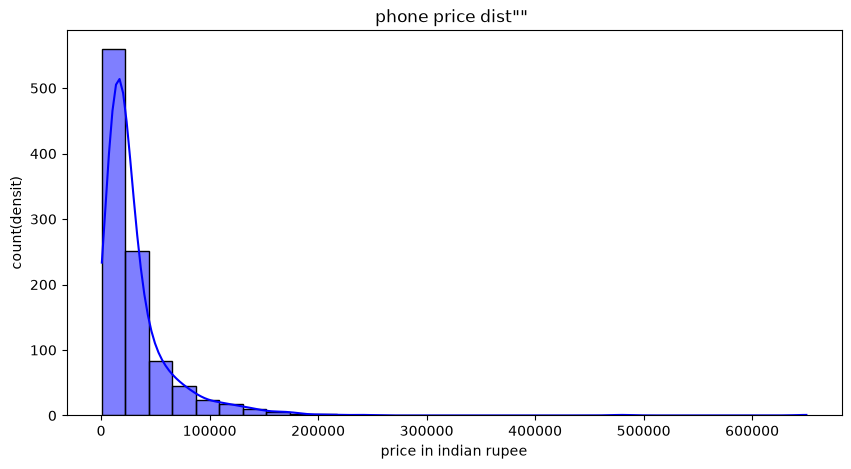

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.histplot(df['price'], kde= True,bins=30,color='blue')
plt.title('phone price dist"" ')
plt.xlabel('price in indian rupee')
plt.ylabel('count(densit)')
plt.show()

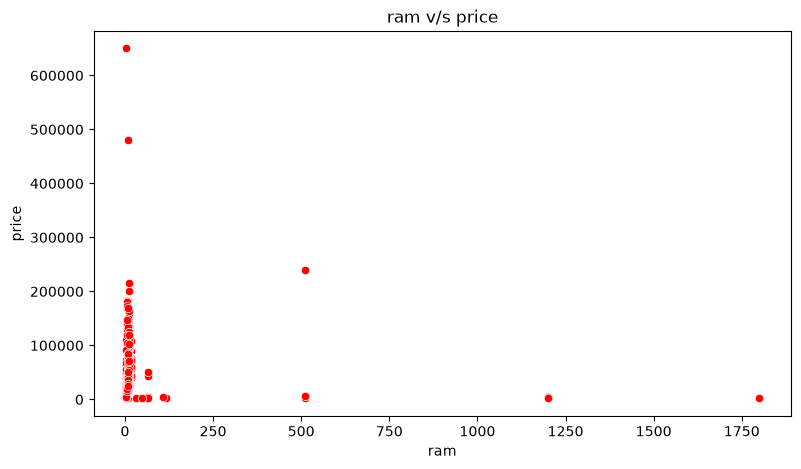

In [15]:
# graph2
plt.figure(figsize=(9,5))
sns.scatterplot(x=df['ram_gb'], y=df['price'], color ='red')
plt.title('ram v/s price')
plt.xlabel('ram')
plt.ylabel('price')
plt.show()
# it has wrong beacuse that will give an wrong scatter plot that becuse... 1250,1750 gb ram dosen't exist so it is an outliers we remove this

In [16]:
# we have an create an new dataframe df_clean that contain's only the ram and price and remove the outliers
df_clean = df[(df['ram_gb']>=1) & (df['ram_gb']<= 24) & (df['price']<=200000)].copy()
print("old data shape and size:-",df.shape)
print("new data shape and size:-",df_clean.shape)


old data shape and size:- (1003, 14)
new data shape and size:- (979, 14)


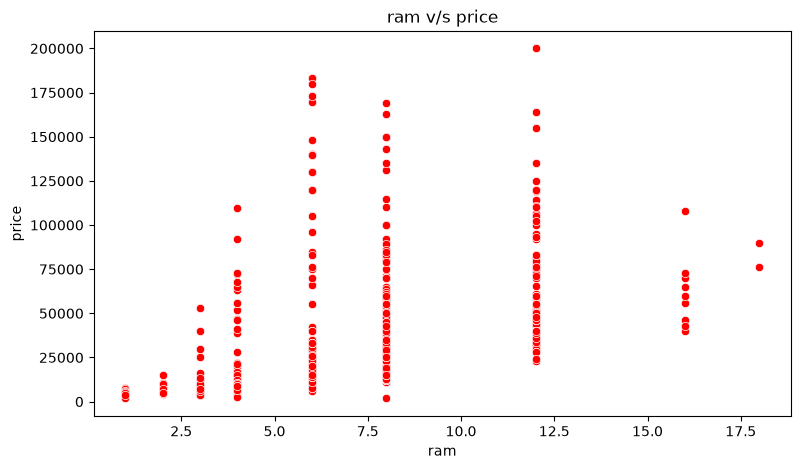

In [17]:
# graph2
plt.figure(figsize=(9,5))
sns.scatterplot(x=df_clean['ram_gb'], y=df_clean['price'], color ='red')
plt.title('ram v/s price')
plt.xlabel('ram')
plt.ylabel('price')
plt.show()

C:\Users\Keshav Gupta\AppData\Local\Temp\ipykernel_4756\2045428951.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='brand', y='price', color ='red', data=df_top_brands,palette='Set2') #palette mean that give an different colour to that for beauty


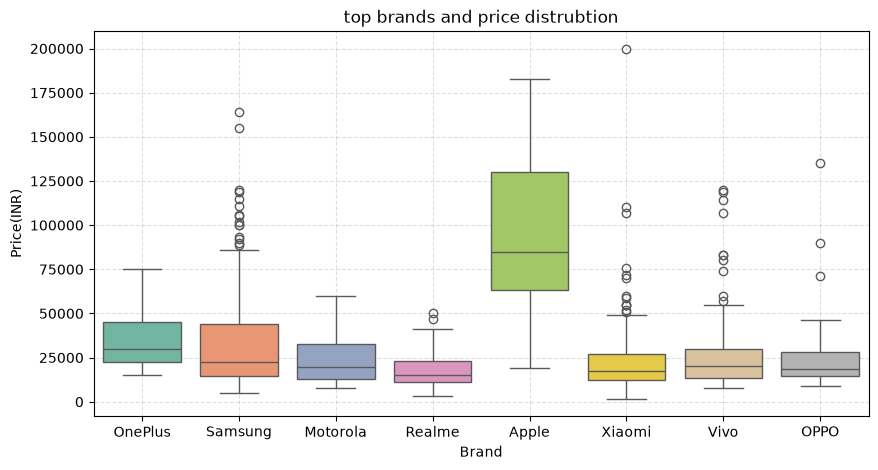

In [18]:
# brand and price 
top_brands = df_clean['brand'].value_counts().head(8).index

df_top_brands = df_clean[df_clean['brand'].isin(top_brands)]
# df_top_brands :-> it is create an new dataframe in which we have only top 8 brands detail's mobile data it is (temporay' dataframe)

plt.figure(figsize=(10,5))
sns.boxplot(x='brand', y='price', color ='red', data=df_top_brands,palette='Set2') #palette mean that give an different colour to that for beauty
plt.title('top brands and price distrubtion')
plt.xlabel('Brand')
plt.ylabel('Price(INR)')
plt.grid(True, linestyle='--', alpha=0.4) #alpha that saw that the brightness of the background line
plt.show()

In [19]:
# <!-- that at above boxplot garph show you that about the price range of the mobile phone that like max or min or mid_value type price range and that also an
# 1). above that box small circle have draw that show an outlier's
# 2). and most below and below just the outilers circle that show an higher and lower value for an mobile phone 
# 3). at the line in the box that show an medain
# 4). upper small circle:- outliers
#     that horizontical line show the max and min limit of mobile phone (we, say that whisker)
#     in box above medain line it is 75%
#     in box below medain line it is 25%
#     in box at medain line it is 50% -->


In [20]:
print(df_top_brands.shape)
print(df_clean.shape)
print(df.shape)

(675, 14)
(979, 14)
(1003, 14)


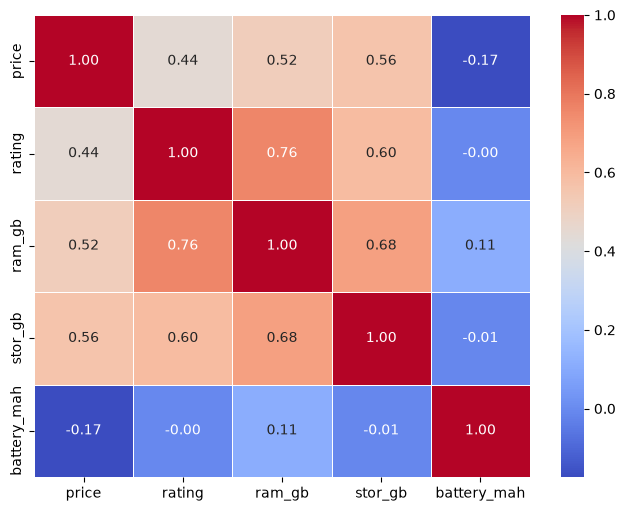

In [21]:
# heatMAp graph
corr_mat = df_clean.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_mat,annot=True,cmap='coolwarm',fmt=".2f",linewidths=0.5)
plt.show()

In [22]:
# <!-- if that we have an " +1 " it show that we can have direct relation to each other , like an we increase the price then ram,storage then we increase the one then other increase automatically..
# then, if we have an " -1 " it show that revrse of the "+1" if any quantity increase then other automatticaly will decrase like an example:->
#     battery and price if we increse the price then battery will be less like an 2500 mAh and if less price then battery will be 6500 mAH 

# then "0" show an no any realtion between then both quantity 

# that more infomation go, on www.google.com and search the explain me an heatmap  -->

In [23]:
print(df_clean.columns)

Index(['model', 'price', 'rating', 'sim', 'processor', 'display', 'camera',
       'card', 'os', 'ram_gb', 'stor_gb', 'battery_mah', 'fast_chr_watt',
       'brand'],
      dtype='str')


# Feature Encoding

In [24]:
features = ['ram_gb','stor_gb','rating','battery_mah','fast_chr_watt','brand']
df_model = df_clean[features + ['price']].dropna().copy()

df_model = pd.get_dummies(df_model, columns=['brand'],drop_first=True)

df_model

,ram_gb,stor_gb,rating,battery_mah,fast_chr_watt,price,brand_Asus,brand_BLU,brand_Blackview,brand_Cola,...,brand_Sony,brand_TCL,brand_Tecno,brand_Tesla,brand_Vivo,brand_Xiaomi,brand_ZTE,brand_iKall,brand_iQOO,brand_itel
0,12.0,256.0,89.0,5000,100,54999,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,6.0,128.0,81.0,5000,33,19989,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,4.0,64.0,75.0,5000,15,16499,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,6.0,128.0,81.0,5000,0,14999,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,6.0,128.0,82.0,5000,67,24999,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,8.0,128.0,83.0,5000,2,34990,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1016,6.0,128.0,75.0,5000,5,14990,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1017,8.0,256.0,85.0,5080,67,28990,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1018,6.0,128.0,80.0,5000,0,19990,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


# Model Training & Evaluation

In [25]:
x = df_model.drop(columns=['price'])
y = df_model['price']


print("features (X) shape:-", x.shape)
print("features (Y) shape:-", y.shape)

features (X) shape:- (875, 49)
features (Y) shape:- (875,)


In [26]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=45)

print("training phone:-",x_train.shape[0])
print("testing phone:-",x_test.shape[0])

#here, we calulate the, test and traing data row and coloum as by the:- 
#  test data = 875 * (20/100) = 175
#  traing data = 49 * (80/100) = 700


training phone:- 700
testing phone:- 175


#linearRegression

In [27]:
# linear regression model:-
# use an scikit learn 

from sklearn.linear_model import LinearRegression
model = LinearRegression()
# while in the x_train we get have an 80% data that have an for traing the model and that answer of the x_train is y_train store so during the fitting we passed 
# both of them qunatity, 
model.fit(x_train,y_train)
print("SUCCESSFULLY!! YOUR MODEL TRAIN----- ")


SUCCESSFULLY!! YOUR MODEL TRAIN----- 


In [28]:
# #get check how data will learn 

from sklearn.metrics import r2_score, mean_absolute_error

y_pred = model.predict(x_test) #take an test of model and we predict the value and store in y_pred

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test,y_pred)

print(f"r2 score:- {r2:.3f}")
print(f"mean abouslte error:- {mae:.2f}")

r2 score:- 0.212
mean abouslte error:- 12633.01


#RandomForestRegressor

In [29]:
# linear regression model:-
# use an scikit learn 

from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=20)
# while in the x_train we get have an 80% data that have an for traing the model and that answer of the x_train is y_train store so during the fitting we passed 
# both of them qunatity, 
rf_model.fit(x_train,y_train)
print("SUCCESSFULLY!! YOUR MODEL TRAIN----- ")



SUCCESSFULLY!! YOUR MODEL TRAIN----- 


In [30]:
rf_pred = rf_model.predict(x_test) #take an test of model and we predict the value and store in y_pred

rf_r2 = r2_score(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test,rf_pred)

print(f"r2 score:- {rf_r2:.3f}")
print(f"mean abouslte error:- {rf_mae:.2f}")

r2 score:- 0.652
mean abouslte error:- 7532.04


In [31]:
# as  according to the model we choose firstly the linear regression that was an linear equation that give an staright line model equation that was not given an correct model
# accuracy

# as the we choose the random_forestlinear_model we have an that an tree type concept and that in the random_forest have many of tree it is an decision tree and this model give 
# an best accuracy 

# Feature Importance & Inference

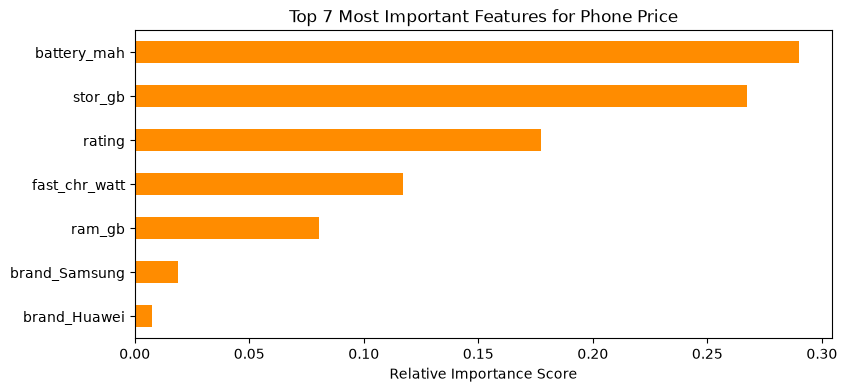

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Features importance 
importance = pd.Series(rf_model.feature_importances_, index=x_train.columns)

# 2. Top 7 important features ka graph
plt.figure(figsize=(9, 4))
importance.nlargest(7).sort_values().plot(kind='barh', color='darkorange')
plt.title('Top 7 Most Important Features for Phone Price')
plt.xlabel('Relative Importance Score')
plt.show()

# in that we get predict the price and that change also

In [ ]:
single_phone = x_test.iloc[[2]]
real_price = y_test.iloc[2]

# Prediction 
predicted_price = rf_model.predict(single_phone)[0]

print(f"REAL Price      : ₹{real_price:,.2f}")
print(f"Predicted Price  : ₹{predicted_price:,.2f}")
print(f"Gap (Difference) : ₹{abs(real_price - predicted_price):,.2f}")

REAL Price      : ₹19,999.00
Predicted Price  : ₹22,698.01
Gap (Difference) : ₹2,699.01


# PREDCTION ON USER's DATA

In [36]:
import pandas as pd

print("=== Enter Smartphone Specifications ===")

# Safe input helper function
def get_float_input(prompt, default_val):
    val = input(prompt).strip()
    try:
        return float(val)
    except ValueError:
        print(f"Invalid number entered, using default value: {default_val}.")
        return float(default_val)

# 1. Collect specifications from the user
u_ram = get_float_input("RAM (in GB, e.g., 6, 8, 12): ", 8.0)
u_storage = get_float_input("Storage (in GB, e.g., 64, 128, 256): ", 128.0)
u_rating = get_float_input("Rating (Dataset scale: 60 to 89, e.g., 80.0): ", 80.0)
u_battery = get_float_input("Battery (in mAh, e.g., 5000): ", 5000.0)
u_charging = get_float_input("Fast Charging (in Watts, e.g., 33, 67): ", 33.0)
u_brand = input("Brand (e.g., OnePlus, Samsung, Realme): ").strip()

# 2. Initialize a 1-row DataFrame matching x_train columns (to prevent dtype conflicts)
user_data = {col: [False if x_train[col].dtype == 'bool' else 0.0] for col in x_train.columns}
user_phone = pd.DataFrame(user_data)

# 3. Assign numerical features
user_phone['ram_gb'] = float(u_ram)
user_phone['stor_gb'] = float(u_storage)
user_phone['rating'] = float(u_rating)
user_phone['battery_mah'] = float(u_battery)
user_phone['fast_chr_watt'] = float(u_charging)

# 4. Apply one-hot encoding for the brand
brand_col = f"brand_{u_brand}"
if brand_col in user_phone.columns:
    user_phone[brand_col] = True

# 5. Predict price
live_price = rf_model.predict(user_phone)[0]

print("\n------------------------------------------")
print(f"Phone: {u_brand} ({int(u_ram)}GB RAM, {int(u_storage)}GB Storage)")
print(f"Estimated Price: ₹{live_price:,.2f}")
print("------------------------------------------")

=== Enter Smartphone Specifications ===
Invalid number entered, using default value: 8.0.
Invalid number entered, using default value: 128.0.
Invalid number entered, using default value: 80.0.
Invalid number entered, using default value: 5000.0.
Invalid number entered, using default value: 33.0.

------------------------------------------
Phone:  (8GB RAM, 128GB Storage)
Estimated Price: ₹16,592.92
------------------------------------------


# --------------------------------!! END !!--------------------------------